In [ ]:
import pandas as pd 
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

In [45]:
pd.set_option('display.max_columns', None)

# Preprocess

In [5]:
ad = pd.read_csv('Advanced box scores 2023.csv')
tr = pd.read_csv('traditional box scores 2023.csv')

In [6]:
ad = ad.drop(columns=['TEAM_NAME','TEAM_ABBREVIATION',
                                                                     'TEAM_CITY','MIN'])
df = pd.merge(tr, ad, on=['GAME_ID', 'TEAM_ID'], how='right')

In [7]:
conditions = [df['MATCHUP'].str.contains('vs.'),
              df['MATCHUP'].str.contains('@')]
choices = ['home', 'away']

df['home_away'] = np.select(conditions, choices, default='unknown')

In [8]:
df['WL']= df['WL'].map({'W': 1, 'L': 0})

In [9]:
df.columns

Index(['Unnamed: 0_x', 'SEASON_ID', 'TEAM_ID', 'TEAM_ABBREVIATION',
       'TEAM_NAME', 'GAME_ID', 'GAME_DATE', 'MATCHUP', 'WL', 'MIN', 'FGM',
       'FGA', 'FG_PCT', 'FG3M', 'FG3A', 'FG3_PCT', 'FTM', 'FTA', 'FT_PCT',
       'OREB', 'DREB', 'REB', 'AST', 'STL', 'BLK', 'TOV', 'PF', 'PTS',
       'PLUS_MINUS', 'VIDEO_AVAILABLE', 'Unnamed: 0_y', 'E_OFF_RATING',
       'OFF_RATING', 'E_DEF_RATING', 'DEF_RATING', 'E_NET_RATING',
       'NET_RATING', 'AST_PCT', 'AST_TOV', 'AST_RATIO', 'OREB_PCT', 'DREB_PCT',
       'REB_PCT', 'E_TM_TOV_PCT', 'TM_TOV_PCT', 'EFG_PCT', 'TS_PCT', 'USG_PCT',
       'E_USG_PCT', 'E_PACE', 'PACE', 'PACE_PER40', 'POSS', 'PIE',
       'home_away'],
      dtype='object')

In [10]:
df.drop(columns=['Unnamed: 0_x', 'Unnamed: 0_y', 'VIDEO_AVAILABLE'], inplace=True)
original_columns = df.columns
original_columns

Index(['SEASON_ID', 'TEAM_ID', 'TEAM_ABBREVIATION', 'TEAM_NAME', 'GAME_ID',
       'GAME_DATE', 'MATCHUP', 'WL', 'MIN', 'FGM', 'FGA', 'FG_PCT', 'FG3M',
       'FG3A', 'FG3_PCT', 'FTM', 'FTA', 'FT_PCT', 'OREB', 'DREB', 'REB', 'AST',
       'STL', 'BLK', 'TOV', 'PF', 'PTS', 'PLUS_MINUS', 'E_OFF_RATING',
       'OFF_RATING', 'E_DEF_RATING', 'DEF_RATING', 'E_NET_RATING',
       'NET_RATING', 'AST_PCT', 'AST_TOV', 'AST_RATIO', 'OREB_PCT', 'DREB_PCT',
       'REB_PCT', 'E_TM_TOV_PCT', 'TM_TOV_PCT', 'EFG_PCT', 'TS_PCT', 'USG_PCT',
       'E_USG_PCT', 'E_PACE', 'PACE', 'PACE_PER40', 'POSS', 'PIE',
       'home_away'],
      dtype='object')

In [11]:
df

,SEASON_ID,TEAM_ID,TEAM_ABBREVIATION,TEAM_NAME,GAME_ID,GAME_DATE,MATCHUP,WL,MIN,FGM,...,EFG_PCT,TS_PCT,USG_PCT,E_USG_PCT,E_PACE,PACE,PACE_PER40,POSS,PIE,home_away
0,22023,1610612756,PHX,Phoenix Suns,22300062,2023-10-24,PHX @ GSW,1,240,42,...,0.500,0.527,1.0,0.198,105.40,101.5,84.58,101,0.564,away
1,22023,1610612744,GSW,Golden State Warriors,22300062,2023-10-24,GSW vs. PHX,0,240,36,...,0.406,0.459,1.0,0.198,105.40,101.5,84.58,102,0.436,home
2,22023,1610612747,LAL,Los Angeles Lakers,22300061,2023-10-24,LAL @ DEN,0,240,41,...,0.511,0.541,1.0,0.199,98.54,95.5,79.58,96,0.421,away
3,22023,1610612743,DEN,Denver Nuggets,22300061,2023-10-24,DEN vs. LAL,1,240,48,...,0.604,0.618,1.0,0.196,98.54,95.5,79.58,95,0.579,home
4,22023,1610612748,MIA,Miami Heat,22300068,2023-10-25,MIA vs. DET,1,240,37,...,0.446,0.498,1.0,0.201,96.52,95.5,79.58,95,0.507,home
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2455,22023,1610612757,POR,Portland Trail Blazers,22301200,2024-04-14,POR @ SAC,0,240,31,...,0.352,0.389,1.0,0.199,100.18,99.0,82.50,99,0.269,away
2456,22023,1610612762,UTA,Utah Jazz,22301198,2024-04-14,UTA @ GSW,0,240,46,...,0.596,0.604,1.0,0.195,101.58,100.0,83.33,100,0.429,away
2457,22023,1610612744,GSW,Golden State Warriors,22301198,2024-04-14,GSW vs. UTA,1,240,45,...,0.553,0.591,1.0,0.200,101.58,100.0,83.33,100,0.571,home
2458,22023,1610612761,TOR,Toronto Raptors,22301189,2024-04-14,TOR @ MIA,0,240,38,...,0.472,0.519,1.0,0.198,103.30,100.0,83.33,99,0.369,away


In [12]:
home = df.loc[(df['WL'] == 1) & (df['home_away'] == 'home')]
away = df.loc[(df['WL'] == 1) & (df['home_away'] == 'away')]


In [13]:
print(len(home))
print(len(away))

668
562


In [14]:
df.GAME_ID.nunique()

1230

In [72]:
df.columns

Index(['SEASON_ID', 'TEAM_ID', 'TEAM_ABBREVIATION', 'TEAM_NAME', 'GAME_ID',
       'GAME_DATE', 'MATCHUP', 'WL', 'MIN', 'FGM', 'FGA', 'FG_PCT', 'FG3M',
       'FG3A', 'FG3_PCT', 'FTM', 'FTA', 'FT_PCT', 'OREB', 'DREB', 'REB', 'AST',
       'STL', 'BLK', 'TOV', 'PF', 'PTS', 'PLUS_MINUS', 'E_OFF_RATING',
       'OFF_RATING', 'E_DEF_RATING', 'DEF_RATING', 'E_NET_RATING',
       'NET_RATING', 'AST_PCT', 'AST_TOV', 'AST_RATIO', 'OREB_PCT', 'DREB_PCT',
       'REB_PCT', 'E_TM_TOV_PCT', 'TM_TOV_PCT', 'EFG_PCT', 'TS_PCT', 'USG_PCT',
       'E_USG_PCT', 'E_PACE', 'PACE', 'PACE_PER40', 'POSS', 'PIE',
       'home_away'],
      dtype='object')

# Create rolling windows

I thought about using the estimated ratings for this but for not I am going to use the normal ones and see how that works. Then later I will probabily come back and try it with the other ones.

I am also going to use a rolling window of 5 games. Later it would be worth it to see if going to 10 games makes a difference. 

In [33]:
# sort the data by team and date
df_roll = df.sort_values(by=['TEAM_ID', 'GAME_DATE'])

In [34]:
rolling_cols = df_roll[['FGM', 'FGA', 'FG_PCT', 'FG3M',
       'FG3A', 'FG3_PCT', 'FTM', 'FTA', 'FT_PCT', 'OREB', 'DREB', 'REB', 'AST',
       'STL', 'BLK', 'TOV', 'PF', 'PTS', 'PLUS_MINUS', 'E_OFF_RATING',
       'OFF_RATING', 'E_DEF_RATING', 'DEF_RATING', 'E_NET_RATING',
       'NET_RATING', 'AST_PCT', 'AST_TOV', 'AST_RATIO', 'OREB_PCT', 'DREB_PCT',
       'REB_PCT', 'E_TM_TOV_PCT', 'TM_TOV_PCT', 'EFG_PCT', 'TS_PCT', 'USG_PCT',
       'E_USG_PCT', 'E_PACE', 'PACE', 'PACE_PER40', 'POSS', 'PIE']]

window_size = 5

for col in rolling_cols:
    df_roll[f'{col}_rolling'] = df_roll.groupby('TEAM_ID')[col].shift(1).rolling(
        window=window_size, min_periods=1
    ).mean().reset_index(level=0, drop=True)


## Drop unneeded columns

In [35]:
list = df_roll.columns.to_list()
print(list)

['SEASON_ID', 'TEAM_ID', 'TEAM_ABBREVIATION', 'TEAM_NAME', 'GAME_ID', 'GAME_DATE', 'MATCHUP', 'WL', 'MIN', 'FGM', 'FGA', 'FG_PCT', 'FG3M', 'FG3A', 'FG3_PCT', 'FTM', 'FTA', 'FT_PCT', 'OREB', 'DREB', 'REB', 'AST', 'STL', 'BLK', 'TOV', 'PF', 'PTS', 'PLUS_MINUS', 'E_OFF_RATING', 'OFF_RATING', 'E_DEF_RATING', 'DEF_RATING', 'E_NET_RATING', 'NET_RATING', 'AST_PCT', 'AST_TOV', 'AST_RATIO', 'OREB_PCT', 'DREB_PCT', 'REB_PCT', 'E_TM_TOV_PCT', 'TM_TOV_PCT', 'EFG_PCT', 'TS_PCT', 'USG_PCT', 'E_USG_PCT', 'E_PACE', 'PACE', 'PACE_PER40', 'POSS', 'PIE', 'home_away', 'FGM_rolling', 'FGA_rolling', 'FG_PCT_rolling', 'FG3M_rolling', 'FG3A_rolling', 'FG3_PCT_rolling', 'FTM_rolling', 'FTA_rolling', 'FT_PCT_rolling', 'OREB_rolling', 'DREB_rolling', 'REB_rolling', 'AST_rolling', 'STL_rolling', 'BLK_rolling', 'TOV_rolling', 'PF_rolling', 'PTS_rolling', 'PLUS_MINUS_rolling', 'E_OFF_RATING_rolling', 'OFF_RATING_rolling', 'E_DEF_RATING_rolling', 'DEF_RATING_rolling', 'E_NET_RATING_rolling', 'NET_RATING_rolling', 'A

In [36]:
df_roll.drop(columns=['MIN', 'FGM', 'FGA', 'FG_PCT', 'FG3M', 'FG3A', 'FG3_PCT', 'FTM', 'FTA', 'FT_PCT', 'OREB', 'DREB', 'REB', 'AST', 'STL', 'BLK', 'TOV', 'PF', 'PTS', 'PLUS_MINUS',
                       'E_OFF_RATING', 'OFF_RATING', 'E_DEF_RATING', 'DEF_RATING', 'E_NET_RATING', 'NET_RATING', 'AST_PCT', 'AST_TOV', 'AST_RATIO', 'OREB_PCT', 'DREB_PCT', 
                       'REB_PCT', 'E_TM_TOV_PCT', 'TM_TOV_PCT', 'EFG_PCT', 'TS_PCT', 'USG_PCT', 'E_USG_PCT', 'E_PACE', 'PACE', 'PACE_PER40', 'POSS', 'PIE'], inplace=True)

In [37]:
df_roll

,SEASON_ID,TEAM_ID,TEAM_ABBREVIATION,TEAM_NAME,GAME_ID,GAME_DATE,MATCHUP,WL,home_away,FGM_rolling,...,TM_TOV_PCT_rolling,EFG_PCT_rolling,TS_PCT_rolling,USG_PCT_rolling,E_USG_PCT_rolling,E_PACE_rolling,PACE_rolling,PACE_PER40_rolling,POSS_rolling,PIE_rolling
11,22023,1610612737,ATL,Atlanta Hawks,22300063,2023-10-25,ATL @ CHA,0,away,40.6,...,16.40,0.55300,0.5976,1.0,0.1994,103.456,102.500,85.4160,102.60,0.48740
45,22023,1610612737,ATL,Atlanta Hawks,22300079,2023-10-27,ATL vs. NYK,0,home,40.6,...,11.14,0.51140,0.5488,1.0,0.1990,102.096,101.400,84.5000,101.40,0.43560
77,22023,1610612737,ATL,Atlanta Hawks,22300097,2023-10-29,ATL @ MIL,1,away,43.4,...,14.60,0.56100,0.5780,1.0,0.1988,100.432,99.166,82.6380,101.20,0.49160
91,22023,1610612737,ATL,Atlanta Hawks,22300104,2023-10-30,ATL vs. MIN,1,home,40.6,...,12.32,0.53220,0.5688,1.0,0.1982,101.278,99.406,82.8360,101.20,0.53740
121,22023,1610612737,ATL,Atlanta Hawks,22300117,2023-11-01,ATL vs. WAS,1,home,43.4,...,11.50,0.56840,0.6046,1.0,0.1986,102.360,100.738,83.9480,102.60,0.50780
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2335,22023,1610612766,CHA,Charlotte Hornets,22301135,2024-04-07,CHA vs. OKC,0,home,42.8,...,13.78,0.53360,0.5568,1.0,0.1988,102.428,99.600,83.0000,99.80,0.44000
2349,22023,1610612766,CHA,Charlotte Hornets,22301144,2024-04-09,CHA vs. DAL,0,home,43.6,...,13.64,0.53400,0.5694,1.0,0.1984,101.452,99.910,83.2580,101.60,0.47640
2382,22023,1610612766,CHA,Charlotte Hornets,22301159,2024-04-10,CHA @ ATL,1,away,42.0,...,15.05,0.51775,0.5605,1.0,0.2000,106.365,104.625,87.1875,104.75,0.47525
2410,22023,1610612766,CHA,Charlotte Hornets,22301173,2024-04-12,CHA @ BOS,0,away,41.0,...,13.02,0.54380,0.5664,1.0,0.1978,100.940,98.900,82.4180,99.00,0.45440


# Create cumulative window

In [50]:
df_avg = df.sort_values(by=['TEAM_ID', 'GAME_DATE'])

average_columns = df_avg[['FGM', 'FGA', 'FG_PCT', 'FG3M',
       'FG3A', 'FG3_PCT', 'FTM', 'FTA', 'FT_PCT', 'OREB', 'DREB', 'REB', 'AST',
       'STL', 'BLK', 'TOV', 'PF', 'PTS', 'PLUS_MINUS', 'E_OFF_RATING',
       'OFF_RATING', 'E_DEF_RATING', 'DEF_RATING', 'E_NET_RATING',
       'NET_RATING', 'AST_PCT', 'AST_TOV', 'AST_RATIO', 'OREB_PCT', 'DREB_PCT',
       'REB_PCT', 'E_TM_TOV_PCT', 'TM_TOV_PCT', 'EFG_PCT', 'TS_PCT', 'USG_PCT',
       'E_USG_PCT', 'E_PACE', 'PACE', 'PACE_PER40', 'POSS', 'PIE']]

for cols in average_columns:
    df_avg[f'{cols}_cum_avg'] = df_avg.groupby('TEAM_ID')[cols].expanding(min_periods=1).mean().reset_index(level=0, drop=True)

df_avg

,SEASON_ID,TEAM_ID,TEAM_ABBREVIATION,TEAM_NAME,GAME_ID,GAME_DATE,MATCHUP,WL,MIN,FGM,FGA,FG_PCT,FG3M,FG3A,FG3_PCT,FTM,FTA,FT_PCT,OREB,DREB,REB,AST,STL,BLK,TOV,PF,PTS,PLUS_MINUS,E_OFF_RATING,OFF_RATING,E_DEF_RATING,DEF_RATING,E_NET_RATING,NET_RATING,AST_PCT,AST_TOV,AST_RATIO,OREB_PCT,DREB_PCT,REB_PCT,E_TM_TOV_PCT,TM_TOV_PCT,EFG_PCT,TS_PCT,USG_PCT,E_USG_PCT,E_PACE,PACE,PACE_PER40,POSS,PIE,home_away,FGM_cum_avg,FGA_cum_avg,FG_PCT_cum_avg,FG3M_cum_avg,FG3A_cum_avg,FG3_PCT_cum_avg,FTM_cum_avg,FTA_cum_avg,FT_PCT_cum_avg,OREB_cum_avg,DREB_cum_avg,REB_cum_avg,AST_cum_avg,STL_cum_avg,BLK_cum_avg,TOV_cum_avg,PF_cum_avg,PTS_cum_avg,PLUS_MINUS_cum_avg,E_OFF_RATING_cum_avg,OFF_RATING_cum_avg,E_DEF_RATING_cum_avg,DEF_RATING_cum_avg,E_NET_RATING_cum_avg,NET_RATING_cum_avg,AST_PCT_cum_avg,AST_TOV_cum_avg,AST_RATIO_cum_avg,OREB_PCT_cum_avg,DREB_PCT_cum_avg,REB_PCT_cum_avg,E_TM_TOV_PCT_cum_avg,TM_TOV_PCT_cum_avg,EFG_PCT_cum_avg,TS_PCT_cum_avg,USG_PCT_cum_avg,E_USG_PCT_cum_avg,E_PACE_cum_avg,PACE_cum_avg,PACE_PER40_cum_avg,POSS_cum_avg,PIE_cum_avg
11,22023,1610612737,ATL,Atlanta Hawks,22300063,2023-10-25,ATL @ CHA,0,240,39,93,0.419,5,29,0.172,27,33,0.818,12,30,42,24,12,1,12,19,110,-6,102.3,105.8,111.1,111.5,-8.8,-5.8,0.615,2.00,16.7,0.276,0.674,0.452,11.161,11.5,0.446,0.512,1.0,0.199,105.98,104.0,86.67,104,0.451,away,39.000000,93.000000,0.419000,5.000000,29.000000,0.172000,27.000000,33.000000,0.818000,12.000000,30.000000,42.000000,24.000000,12.000000,1.000000,12.000000,19.000000,110.000000,-6.000000,102.300000,105.800000,111.100000,111.500000,-8.800000,-5.800000,0.615000,2.000000,16.700000,0.276000,0.674000,0.452000,11.161000,11.500000,0.446000,0.512000,1.0,0.199000,105.980000,104.000000,86.670000,104.000000,0.451000
45,22023,1610612737,ATL,Atlanta Hawks,22300079,2023-10-27,ATL vs. NYK,0,240,42,87,0.483,12,32,0.375,24,30,0.800,9,35,44,28,7,6,14,20,120,-6,114.1,111.1,118.5,118.9,-4.4,-7.8,0.667,2.00,19.7,0.255,0.706,0.490,13.308,13.0,0.552,0.599,1.0,0.201,105.76,107.0,89.17,108,0.495,home,40.500000,90.000000,0.451000,8.500000,30.500000,0.273500,25.500000,31.500000,0.809000,10.500000,32.500000,43.000000,26.000000,9.500000,3.500000,13.000000,19.500000,115.000000,-6.000000,108.200000,108.450000,114.800000,115.200000,-6.600000,-6.800000,0.641000,2.000000,18.200000,0.265500,0.690000,0.471000,12.234500,12.250000,0.499000,0.555500,1.0,0.200000,105.870000,105.500000,87.920000,106.000000,0.473000
77,22023,1610612737,ATL,Atlanta Hawks,22300097,2023-10-29,ATL @ MIL,1,240,47,93,0.505,15,37,0.405,18,22,0.818,13,33,46,32,15,2,17,17,127,17,119.0,122.1,104.0,107.8,15.1,14.3,0.681,1.88,21.1,0.396,0.694,0.546,15.936,16.3,0.586,0.618,1.0,0.199,106.24,103.0,85.83,104,0.618,away,42.666667,91.000000,0.469000,10.666667,32.666667,0.317333,23.000000,28.333333,0.812000,11.333333,32.666667,44.000000,28.000000,11.333333,3.000000,14.333333,18.666667,119.000000,1.666667,111.800000,113.000000,111.200000,112.733333,0.633333,0.233333,0.654333,1.960000,19.166667,0.309000,0.691333,0.496000,13.468333,13.600000,0.528000,0.576333,1.0,0.199667,105.993333,104.666667,87.223333,105.333333,0.521333
91,22023,1610612737,ATL,Atlanta Hawks,22300104,2023-10-30,ATL vs. MIN,1,240,48,86,0.558,14,30,0.467,17,18,0.944,4,32,36,28,6,7,11,12,127,14,125.8,130.9,112.3,114.1,13.5,16.8,0.583,2.55,21.1,0.184,0.688,0.465,10.900,11.3,0.640,0.676,1.0,0.194,100.76,98.0,81.67,97,0.591,home,44.000000,89.750000,0.491250,11.500000,32.000000,0.354750,21.500000,25.750000,0.845000,9.500000,32.500000,42.000000,28.000000,10.000000,4.000000,13.500000,17.000000,121.000000,4.750000,115.300000,117.475000,111.475000,113.075000,3.850000,4.375000,0.636500,2.107500,19.650000,0.277750,0.690500,0.488250,12.826250,13.025000,0.556000,0.601250,1.0,0.198250,104.685000,103.000000,85.835000,103.250000,0.538750
121,22023,1610612737,ATL,Atlanta Hawks,22300117,2023-11-01,ATL vs. WAS,1,240,46,92,0.500,9,32,0.281,29,32,0.906,14,43,57,26,8,3,21,16,130,9,115.0,118.2,107.9,109.0,7.1,9.2,0.565,1.24,17.0,0.362,0.827,0.606,18.571,19.1,0.549,0.613

## Drop unneeded columns

In [51]:
df_avg.drop(columns=['MIN', 'FGM', 'FGA', 'FG_PCT', 'FG3M', 'FG3A', 'FG3_PCT', 'FTM', 'FTA', 'FT_PCT', 'OREB', 'DREB', 'REB', 'AST', 'STL', 'BLK', 'TOV', 'PF', 'PTS', 'PLUS_MINUS',
                       'E_OFF_RATING', 'OFF_RATING', 'E_DEF_RATING', 'DEF_RATING', 'E_NET_RATING', 'NET_RATING', 'AST_PCT', 'AST_TOV', 'AST_RATIO', 'OREB_PCT', 'DREB_PCT', 
                       'REB_PCT', 'E_TM_TOV_PCT', 'TM_TOV_PCT', 'EFG_PCT', 'TS_PCT', 'USG_PCT', 'E_USG_PCT', 'E_PACE', 'PACE', 'PACE_PER40', 'POSS', 'PIE'], inplace=True)

In [52]:
df_avg

,SEASON_ID,TEAM_ID,TEAM_ABBREVIATION,TEAM_NAME,GAME_ID,GAME_DATE,MATCHUP,WL,home_away,FGM_cum_avg,FGA_cum_avg,FG_PCT_cum_avg,FG3M_cum_avg,FG3A_cum_avg,FG3_PCT_cum_avg,FTM_cum_avg,FTA_cum_avg,FT_PCT_cum_avg,OREB_cum_avg,DREB_cum_avg,REB_cum_avg,AST_cum_avg,STL_cum_avg,BLK_cum_avg,TOV_cum_avg,PF_cum_avg,PTS_cum_avg,PLUS_MINUS_cum_avg,E_OFF_RATING_cum_avg,OFF_RATING_cum_avg,E_DEF_RATING_cum_avg,DEF_RATING_cum_avg,E_NET_RATING_cum_avg,NET_RATING_cum_avg,AST_PCT_cum_avg,AST_TOV_cum_avg,AST_RATIO_cum_avg,OREB_PCT_cum_avg,DREB_PCT_cum_avg,REB_PCT_cum_avg,E_TM_TOV_PCT_cum_avg,TM_TOV_PCT_cum_avg,EFG_PCT_cum_avg,TS_PCT_cum_avg,USG_PCT_cum_avg,E_USG_PCT_cum_avg,E_PACE_cum_avg,PACE_cum_avg,PACE_PER40_cum_avg,POSS_cum_avg,PIE_cum_avg
11,22023,1610612737,ATL,Atlanta Hawks,22300063,2023-10-25,ATL @ CHA,0,away,39.000000,93.000000,0.419000,5.000000,29.000000,0.172000,27.000000,33.000000,0.818000,12.000000,30.000000,42.000000,24.000000,12.000000,1.000000,12.000000,19.000000,110.000000,-6.000000,102.300000,105.800000,111.100000,111.500000,-8.800000,-5.800000,0.615000,2.000000,16.700000,0.276000,0.674000,0.452000,11.161000,11.500000,0.446000,0.512000,1.0,0.199000,105.980000,104.000000,86.670000,104.000000,0.451000
45,22023,1610612737,ATL,Atlanta Hawks,22300079,2023-10-27,ATL vs. NYK,0,home,40.500000,90.000000,0.451000,8.500000,30.500000,0.273500,25.500000,31.500000,0.809000,10.500000,32.500000,43.000000,26.000000,9.500000,3.500000,13.000000,19.500000,115.000000,-6.000000,108.200000,108.450000,114.800000,115.200000,-6.600000,-6.800000,0.641000,2.000000,18.200000,0.265500,0.690000,0.471000,12.234500,12.250000,0.499000,0.555500,1.0,0.200000,105.870000,105.500000,87.920000,106.000000,0.473000
77,22023,1610612737,ATL,Atlanta Hawks,22300097,2023-10-29,ATL @ MIL,1,away,42.666667,91.000000,0.469000,10.666667,32.666667,0.317333,23.000000,28.333333,0.812000,11.333333,32.666667,44.000000,28.000000,11.333333,3.000000,14.333333,18.666667,119.000000,1.666667,111.800000,113.000000,111.200000,112.733333,0.633333,0.233333,0.654333,1.960000,19.166667,0.309000,0.691333,0.496000,13.468333,13.600000,0.528000,0.576333,1.0,0.199667,105.993333,104.666667,87.223333,105.333333,0.521333
91,22023,1610612737,ATL,Atlanta Hawks,22300104,2023-10-30,ATL vs. MIN,1,home,44.000000,89.750000,0.491250,11.500000,32.000000,0.354750,21.500000,25.750000,0.845000,9.500000,32.500000,42.000000,28.000000,10.000000,4.000000,13.500000,17.000000,121.000000,4.750000,115.300000,117.475000,111.475000,113.075000,3.850000,4.375000,0.636500,2.107500,19.650000,0.277750,0.690500,0.488250,12.826250,13.025000,0.556000,0.601250,1.0,0.198250,104.685000,103.000000,85.835000,103.250000,0.538750
121,22023,1610612737,ATL,Atlanta Hawks,22300117,2023-11-01,ATL vs. WAS,1,home,44.400000,90.200000,0.493000,11.000000,32.000000,0.340000,23.000000,27.000000,0.857200,10.400000,34.600000,45.000000,27.600000,9.600000,3.800000,15.000000,16.800000,122.800000,5.600000,115.240000,117.620000,110.760000,112.260000,4.500000,5.340000,0.622200,1.934000,19.120000,0.294600,0.717800,0.511800,13.975200,14.240000,0.554600,0.603600,1.0,0.198000,106.272000,104.500000,87.084000,104.600000,0.539400
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2335,22023,1610612766,CHA,Charlotte Hornets,22301135,2024-04-07,CHA vs. OKC,0,home,40.051282,87.153846,0.460872,11.935897,33.910256,0.350897,14.410256,18.410256,0.785654,9.461538,30.935897,40.397436,24.717949,6.794872,4.487179,13.756410,18.102564,106.448718,-10.153846,107.007692,108.557692,116.903846,119.203846,-9.901282,-10.637179,0.617846,2.015769,18.416667,0.254051,0.714128,0.476551,13.806333,14.012821,0.529795,0.560615,1.0,0.197718,99.445513,97.751795,81.460000,98.089744,0.446718
2349,22023,1610612766,CHA,Charlotte Hornets,22301144,2024-04-09,CHA vs. DAL,0,home,40.037975,87.177215,0.460582,11.911392,33.886076,0.350418,14.430380,18.44303

# Set data up to be modeled

## For cume data

In [73]:
# Split into home and away datasets
home_data_cum = df_avg[df_avg['home_away'] == 'home'].copy()
away_data_cum = df_avg[df_avg['home_away'] == 'away'].copy()

# # Rename columns for clarity
home_data_cum = home_data_cum.rename(columns=lambda x: f"{x}_home" if x not in ['GAME_ID', 'WL'] else x)
away_data_cum = away_data_cum.rename(columns=lambda x: f"{x}_away" if x not in ['GAME_ID', 'WL'] else x)

# Merge home and away data on GAME_ID
game_data_cum = pd.merge(home_data_cum, away_data_cum, on='GAME_ID', suffixes=('_home', '_away'))

# Define the target variable (Home Team Win/Loss)
game_data_cum['WL'] = game_data_cum['WL_home']


In [74]:
game_data_cum

,SEASON_ID_home,TEAM_ID_home,TEAM_ABBREVIATION_home,TEAM_NAME_home,GAME_ID,GAME_DATE_home,MATCHUP_home,WL_home,home_away_home,FGM_cum_avg_home,FGA_cum_avg_home,FG_PCT_cum_avg_home,FG3M_cum_avg_home,FG3A_cum_avg_home,FG3_PCT_cum_avg_home,FTM_cum_avg_home,FTA_cum_avg_home,FT_PCT_cum_avg_home,OREB_cum_avg_home,DREB_cum_avg_home,REB_cum_avg_home,AST_cum_avg_home,STL_cum_avg_home,BLK_cum_avg_home,TOV_cum_avg_home,PF_cum_avg_home,PTS_cum_avg_home,PLUS_MINUS_cum_avg_home,E_OFF_RATING_cum_avg_home,OFF_RATING_cum_avg_home,E_DEF_RATING_cum_avg_home,DEF_RATING_cum_avg_home,E_NET_RATING_cum_avg_home,NET_RATING_cum_avg_home,AST_PCT_cum_avg_home,AST_TOV_cum_avg_home,AST_RATIO_cum_avg_home,OREB_PCT_cum_avg_home,DREB_PCT_cum_avg_home,REB_PCT_cum_avg_home,E_TM_TOV_PCT_cum_avg_home,TM_TOV_PCT_cum_avg_home,EFG_PCT_cum_avg_home,TS_PCT_cum_avg_home,USG_PCT_cum_avg_home,E_USG_PCT_cum_avg_home,E_PACE_cum_avg_home,PACE_cum_avg_home,PACE_PER40_cum_avg_home,POSS_cum_avg_home,PIE_cum_avg_home,SEASON_ID_away,TEAM_ID_away,TEAM_ABBREVIATION_away,TEAM_NAME_away,GAME_DATE_away,MATCHUP_away,WL_away,home_away_away,FGM_cum_avg_away,FGA_cum_avg_away,FG_PCT_cum_avg_away,FG3M_cum_avg_away,FG3A_cum_avg_away,FG3_PCT_cum_avg_away,FTM_cum_avg_away,FTA_cum_avg_away,FT_PCT_cum_avg_away,OREB_cum_avg_away,DREB_cum_avg_away,REB_cum_avg_away,AST_cum_avg_away,STL_cum_avg_away,BLK_cum_avg_away,TOV_cum_avg_away,PF_cum_avg_away,PTS_cum_avg_away,PLUS_MINUS_cum_avg_away,E_OFF_RATING_cum_avg_away,OFF_RATING_cum_avg_away,E_DEF_RATING_cum_avg_away,DEF_RATING_cum_avg_away,E_NET_RATING_cum_avg_away,NET_RATING_cum_avg_away,AST_PCT_cum_avg_away,AST_TOV_cum_avg_away,AST_RATIO_cum_avg_away,OREB_PCT_cum_avg_away,DREB_PCT_cum_avg_away,REB_PCT_cum_avg_away,E_TM_TOV_PCT_cum_avg_away,TM_TOV_PCT_cum_avg_away,EFG_PCT_cum_avg_away,TS_PCT_cum_avg_away,USG_PCT_cum_avg_away,E_USG_PCT_cum_avg_away,E_PACE_cum_avg_away,PACE_cum_avg_away,PACE_PER40_cum_avg_away,POSS_cum_avg_away,PIE_cum_avg_away,WL
0,22023,1610612737,ATL,Atlanta Hawks,22300079,2023-10-27,ATL vs. NYK,0,home,40.500000,90.000000,0.451000,8.500000,30.500000,0.273500,25.500000,31.500000,0.809000,10.500000,32.500000,43.000000,26.000000,9.500000,3.500000,13.000000,19.500000,115.000000,-6.000000,108.200000,108.450000,114.800000,115.200000,-6.600000,-6.800000,0.641000,2.000000,18.200000,0.265500,0.690000,0.471000,12.234500,12.250000,0.499000,0.555500,1.0,0.200000,105.870000,105.500000,87.920000,106.000000,0.473000,22023,1610612752,NYK,New York Knicks,2023-10-27,NYK @ ATL,1,away,39.500000,93.500000,0.424500,19.000000,42.500000,0.447000,17.000000,27.000000,0.626000,14.500000,31.500000,46.000000,27.000000,9.000000,3.000000,13.500000,21.500000,115.000000,1.000000,110.000000,113.050000,114.250000,111.800000,-4.200000,1.250000,0.682500,2.030000,18.450000,0.329000,0.787000,0.526000,12.893500,13.200000,0.526500,0.548000,1.0,0.198500,102.100000,101.750000,84.795000,101.500000,0.456500,0
1,22023,1610612737,ATL,Atlanta Hawks,22300104,2023-10-30,ATL vs. MIN,1,home,44.000000,89.750000,0.491250,11.500000,32.000000,0.354750,21.500000,25.750000,0.845000,9.500000,32.500000,42.000000,28.000000,10.000000,4.000000,13.500000,17.000000,121.000000,4.750000,115.300000,117.475000,111.475000,113.075000,3.850000,4.375000,0.636500,2.107500,19.650000,0.277750,0.690500,0.488250,12.826250,13.025000,0.556000,0.601250,1.0,0.198250,104.685000,103.000000,85.835000,103.250000,0.538750,22023,1610612750,MIN,Minnesota Timberwolves,2023-10-30,MIN @ ATL,0,away,40.666667,92.000000,0.447000,12.000000,32.666667,0.365333,11.000000,15.000000,0.722667,11.000000,38.000000,49.000000,24.666667,7.333333,5.666667,14.666667,16.000000,104.333333,-0.333333,102.400000,104.766667,103.566667,106.233333,-1.166667,-1.533333,0.605000,1.673333,17.933333,0.295333,0.794333,0.537667,14.386000,14.733333,0.513000,0.535333,1.0,0.196000,101.653333,99.166667,82.640000,99.666667,0.498000,1
2,22023,1610612737,ATL,Atlanta Hawks,22300117,2023-11-01,ATL vs. WAS,1,home,44.400000,90.200000,0.493000,11.000000,32.000000,0.

### Drop unneccisary columns

### get difference between home and away stats

In [75]:
# Calculate differences between home and away stats
# stat_columns = ['FGM_cum_avg_home', 'FGA_cum_avg_home', 'FG_PCT_cum_avg_home', 'FG3M_cum_avg_home', 'FG3A_cum_avg_home', 'FG3_PCT_cum_avg_home', 'FTM_cum_avg_home', 
#                 'FTA_cum_avg_home', 'FT_PCT_cum_avg_home', 'OREB_cum_avg_home', 'DREB_cum_avg_home', 'REB_cum_avg_home', 'AST_cum_avg_home', 'STL_cum_avg_home', 
#                 'BLK_cum_avg_home', 'TOV_cum_avg_home', 'PF_cum_avg_home', 'PTS_cum_avg_home', 'PLUS_MINUS_cum_avg_home', 'E_OFF_RATING_cum_avg_home', 'OFF_RATING_cum_avg_home', 
#                 'E_DEF_RATING_cum_avg_home', 'DEF_RATING_cum_avg_home', 'E_NET_RATING_cum_avg_home', 'NET_RATING_cum_avg_home', 'AST_PCT_cum_avg_home', 'AST_TOV_cum_avg_home', 
#                 'AST_RATIO_cum_avg_home', 'OREB_PCT_cum_avg_home', 'DREB_PCT_cum_avg_home', 'REB_PCT_cum_avg_home', 'E_TM_TOV_PCT_cum_avg_home', 'TM_TOV_PCT_cum_avg_home', 
#                 'EFG_PCT_cum_avg_home', 'TS_PCT_cum_avg_home', 'USG_PCT_cum_avg_home', 'E_USG_PCT_cum_avg_home', 'E_PACE_cum_avg_home', 'PACE_cum_avg_home', 
#                 'PACE_PER40_cum_avg_home', 'POSS_cum_avg_home', 'PIE_cum_avg_home','FGM_cum_avg_away', 'FGA_cum_avg_away', 'FG_PCT_cum_avg_away', 'FG3M_cum_avg_away', 
#                 'FG3A_cum_avg_away', 'FG3_PCT_cum_avg_away', 'FTM_cum_avg_away', 'FTA_cum_avg_away', 'FT_PCT_cum_avg_away', 'OREB_cum_avg_away', 'DREB_cum_avg_away', 
#                 'REB_cum_avg_away', 'AST_cum_avg_away', 'STL_cum_avg_away', 'BLK_cum_avg_away', 'TOV_cum_avg_away', 'PF_cum_avg_away', 'PTS_cum_avg_away', 'PLUS_MINUS_cum_avg_away', 
#                 'E_OFF_RATING_cum_avg_away', 'OFF_RATING_cum_avg_away', 'E_DEF_RATING_cum_avg_away', 'DEF_RATING_cum_avg_away', 'E_NET_RATING_cum_avg_away', 
#                 'NET_RATING_cum_avg_away', 'AST_PCT_cum_avg_away', 'AST_TOV_cum_avg_away', 'AST_RATIO_cum_avg_away', 'OREB_PCT_cum_avg_away', 'DREB_PCT_cum_avg_away', 
#                 'REB_PCT_cum_avg_away', 'E_TM_TOV_PCT_cum_avg_away', 'TM_TOV_PCT_cum_avg_away', 'EFG_PCT_cum_avg_away', 'TS_PCT_cum_avg_away', 'USG_PCT_cum_avg_away', 
#                 'E_USG_PCT_cum_avg_away', 'E_PACE_cum_avg_away', 'PACE_cum_avg_away', 'PACE_PER40_cum_avg_away', 'POSS_cum_avg_away', 'PIE_cum_avg_away']

stat_columns = ['FGM_cum_avg', 'FGA_cum_avg', 'FG_PCT_cum_avg', 'FG3M_cum_avg', 'FG3A_cum_avg', 'FG3_PCT_cum_avg', 'FTM_cum_avg', 
                'FTA_cum_avg', 'FT_PCT_cum_avg', 'OREB_cum_avg', 'DREB_cum_avg', 'REB_cum_avg', 'AST_cum_avg', 'STL_cum_avg', 
                'BLK_cum_avg', 'TOV_cum_avg', 'PF_cum_avg', 'PTS_cum_avg', 'PLUS_MINUS_cum_avg', 'E_OFF_RATING_cum_avg', 'OFF_RATING_cum_avg', 
                'E_DEF_RATING_cum_avg', 'DEF_RATING_cum_avg', 'E_NET_RATING_cum_avg', 'NET_RATING_cum_avg', 'AST_PCT_cum_avg', 'AST_TOV_cum_avg', 
                'AST_RATIO_cum_avg', 'OREB_PCT_cum_avg', 'DREB_PCT_cum_avg', 'REB_PCT_cum_avg', 'E_TM_TOV_PCT_cum_avg', 'TM_TOV_PCT_cum_avg', 
                'EFG_PCT_cum_avg', 'TS_PCT_cum_avg','E_PACE_cum_avg', 'PACE_cum_avg', 
                'PACE_PER40_cum_avg', 'POSS_cum_avg', 'PIE_cum_avg']

# Calculate differences for the selected stat columns
for metric in stat_columns:
    home_col = f'{metric}_home'
    away_col = f'{metric}_away'
    diff_col = f'{metric}_diff'
    #if home_col in game_data_cum.columns and away_col in game_data_cum.columns:
    game_data_cum[diff_col] = game_data_cum[home_col] - game_data_cum[away_col]

# Display the resulting dataframe with the new difference columns
game_data_cum


,SEASON_ID_home,TEAM_ID_home,TEAM_ABBREVIATION_home,TEAM_NAME_home,GAME_ID,GAME_DATE_home,MATCHUP_home,WL_home,home_away_home,FGM_cum_avg_home,FGA_cum_avg_home,FG_PCT_cum_avg_home,FG3M_cum_avg_home,FG3A_cum_avg_home,FG3_PCT_cum_avg_home,FTM_cum_avg_home,FTA_cum_avg_home,FT_PCT_cum_avg_home,OREB_cum_avg_home,DREB_cum_avg_home,REB_cum_avg_home,AST_cum_avg_home,STL_cum_avg_home,BLK_cum_avg_home,TOV_cum_avg_home,PF_cum_avg_home,PTS_cum_avg_home,PLUS_MINUS_cum_avg_home,E_OFF_RATING_cum_avg_home,OFF_RATING_cum_avg_home,E_DEF_RATING_cum_avg_home,DEF_RATING_cum_avg_home,E_NET_RATING_cum_avg_home,NET_RATING_cum_avg_home,AST_PCT_cum_avg_home,AST_TOV_cum_avg_home,AST_RATIO_cum_avg_home,OREB_PCT_cum_avg_home,DREB_PCT_cum_avg_home,REB_PCT_cum_avg_home,E_TM_TOV_PCT_cum_avg_home,TM_TOV_PCT_cum_avg_home,EFG_PCT_cum_avg_home,TS_PCT_cum_avg_home,USG_PCT_cum_avg_home,E_USG_PCT_cum_avg_home,E_PACE_cum_avg_home,PACE_cum_avg_home,PACE_PER40_cum_avg_home,POSS_cum_avg_home,PIE_cum_avg_home,SEASON_ID_away,TEAM_ID_away,TEAM_ABBREVIATION_away,TEAM_NAME_away,GAME_DATE_away,MATCHUP_away,WL_away,home_away_away,FGM_cum_avg_away,FGA_cum_avg_away,FG_PCT_cum_avg_away,FG3M_cum_avg_away,FG3A_cum_avg_away,FG3_PCT_cum_avg_away,FTM_cum_avg_away,FTA_cum_avg_away,FT_PCT_cum_avg_away,OREB_cum_avg_away,DREB_cum_avg_away,REB_cum_avg_away,AST_cum_avg_away,STL_cum_avg_away,BLK_cum_avg_away,TOV_cum_avg_away,PF_cum_avg_away,PTS_cum_avg_away,PLUS_MINUS_cum_avg_away,E_OFF_RATING_cum_avg_away,OFF_RATING_cum_avg_away,E_DEF_RATING_cum_avg_away,DEF_RATING_cum_avg_away,E_NET_RATING_cum_avg_away,NET_RATING_cum_avg_away,AST_PCT_cum_avg_away,AST_TOV_cum_avg_away,AST_RATIO_cum_avg_away,OREB_PCT_cum_avg_away,DREB_PCT_cum_avg_away,REB_PCT_cum_avg_away,E_TM_TOV_PCT_cum_avg_away,TM_TOV_PCT_cum_avg_away,EFG_PCT_cum_avg_away,TS_PCT_cum_avg_away,USG_PCT_cum_avg_away,E_USG_PCT_cum_avg_away,E_PACE_cum_avg_away,PACE_cum_avg_away,PACE_PER40_cum_avg_away,POSS_cum_avg_away,PIE_cum_avg_away,WL,FGM_cum_avg_diff,FGA_cum_avg_diff,FG_PCT_cum_avg_diff,FG3M_cum_avg_diff,FG3A_cum_avg_diff,FG3_PCT_cum_avg_diff,FTM_cum_avg_diff,FTA_cum_avg_diff,FT_PCT_cum_avg_diff,OREB_cum_avg_diff,DREB_cum_avg_diff,REB_cum_avg_diff,AST_cum_avg_diff,STL_cum_avg_diff,BLK_cum_avg_diff,TOV_cum_avg_diff,PF_cum_avg_diff,PTS_cum_avg_diff,PLUS_MINUS_cum_avg_diff,E_OFF_RATING_cum_avg_diff,OFF_RATING_cum_avg_diff,E_DEF_RATING_cum_avg_diff,DEF_RATING_cum_avg_diff,E_NET_RATING_cum_avg_diff,NET_RATING_cum_avg_diff,AST_PCT_cum_avg_diff,AST_TOV_cum_avg_diff,AST_RATIO_cum_avg_diff,OREB_PCT_cum_avg_diff,DREB_PCT_cum_avg_diff,REB_PCT_cum_avg_diff,E_TM_TOV_PCT_cum_avg_diff,TM_TOV_PCT_cum_avg_diff,EFG_PCT_cum_avg_diff,TS_PCT_cum_avg_diff,E_PACE_cum_avg_diff,PACE_cum_avg_diff,PACE_PER40_cum_avg_diff,POSS_cum_avg_diff,PIE_cum_avg_diff
0,22023,1610612737,ATL,Atlanta Hawks,22300079,2023-10-27,ATL vs. NYK,0,home,40.500000,90.000000,0.451000,8.500000,30.500000,0.273500,25.500000,31.500000,0.809000,10.500000,32.500000,43.000000,26.000000,9.500000,3.500000,13.000000,19.500000,115.000000,-6.000000,108.200000,108.450000,114.800000,115.200000,-6.600000,-6.800000,0.641000,2.000000,18.200000,0.265500,0.690000,0.471000,12.234500,12.250000,0.499000,0.555500,1.0,0.200000,105.870000,105.500000,87.920000,106.000000,0.473000,22023,1610612752,NYK,New York Knicks,2023-10-27,NYK @ ATL,1,away,39.500000,93.500000,0.424500,19.000000,42.500000,0.447000,17.000000,27.000000,0.626000,14.500000,31.500000,46.000000,27.000000,9.000000,3.000000,13.500000,21.500000,115.000000,1.000000,110.000000,113.050000,114.250000,111.800000,-4.200000,1.250000,0.682500,2.030000,18.450000,0.329000,0.787000,0.526000,12.893500,13.200000,0.526500,0.548000,1.0,0.198500,102.100000,101.750000,84.795000,101.500000,0.456500,0,1.000000,-3.500000,0.026500,-10.500000,-12.000000,-0.173500,8.500000,4.500000,0.183000,-4.000000,1.000000,-3.000000,-1.000000,0.500000,0.500000,-0.500000,-2.000000,0.000000,-7.000000,-1.800000,-4.600000,0.550000,3.400000,-2.400000,-8.050000,-0.041500,-0.030000,-0.250000,-0.063

In [76]:
game_data_cum.drop(columns=["WL_home",
    "home_away_home",
    "FGM_cum_avg_home",
    "FGA_cum_avg_home",
    "FG_PCT_cum_avg_home",
    "FG3M_cum_avg_home",
    "FG3A_cum_avg_home",
    "FG3_PCT_cum_avg_home",
    "FTM_cum_avg_home",
    "FTA_cum_avg_home",
    "FT_PCT_cum_avg_home",
    "OREB_cum_avg_home",
    "DREB_cum_avg_home",
    "REB_cum_avg_home",
    "AST_cum_avg_home",
    "STL_cum_avg_home",
    "BLK_cum_avg_home",
    "TOV_cum_avg_home",
    "PF_cum_avg_home",
    "PTS_cum_avg_home",
    "PLUS_MINUS_cum_avg_home",
    "E_OFF_RATING_cum_avg_home",
    "OFF_RATING_cum_avg_home",
    "E_DEF_RATING_cum_avg_home",
    "DEF_RATING_cum_avg_home",
    "E_NET_RATING_cum_avg_home",
    "NET_RATING_cum_avg_home",
    "AST_PCT_cum_avg_home",
    "AST_TOV_cum_avg_home",
    "AST_RATIO_cum_avg_home",
    "OREB_PCT_cum_avg_home",
    "DREB_PCT_cum_avg_home",
    "REB_PCT_cum_avg_home",
    "E_TM_TOV_PCT_cum_avg_home",
    "TM_TOV_PCT_cum_avg_home",
    "EFG_PCT_cum_avg_home",
    "TS_PCT_cum_avg_home",
    "USG_PCT_cum_avg_home",
    "E_USG_PCT_cum_avg_home",
    "E_PACE_cum_avg_home",
    "PACE_cum_avg_home",
    "PACE_PER40_cum_avg_home",
    "POSS_cum_avg_home",
    "PIE_cum_avg_home",
    "SEASON_ID_away",
    "GAME_DATE_away",
    "MATCHUP_away",
    "WL_away",
    "home_away_away",
    "FGM_cum_avg_away",
    "FGA_cum_avg_away",
    "FG_PCT_cum_avg_away",
    "FG3M_cum_avg_away",
    "FG3A_cum_avg_away",
    "FG3_PCT_cum_avg_away",
    "FTM_cum_avg_away",
    "FTA_cum_avg_away",
    "FT_PCT_cum_avg_away",
    "OREB_cum_avg_away",
    "DREB_cum_avg_away",
    "REB_cum_avg_away",
    "AST_cum_avg_away",
    "STL_cum_avg_away",
    "BLK_cum_avg_away",
    "TOV_cum_avg_away",
    "PF_cum_avg_away",
    "PTS_cum_avg_away",
    "PLUS_MINUS_cum_avg_away",
    "E_OFF_RATING_cum_avg_away",
    "OFF_RATING_cum_avg_away",
    "E_DEF_RATING_cum_avg_away",
    "DEF_RATING_cum_avg_away",
    "E_NET_RATING_cum_avg_away",
    "NET_RATING_cum_avg_away",
    "AST_PCT_cum_avg_away",
    "AST_TOV_cum_avg_away",
    "AST_RATIO_cum_avg_away",
    "OREB_PCT_cum_avg_away",
    "DREB_PCT_cum_avg_away",
    "REB_PCT_cum_avg_away",
    "E_TM_TOV_PCT_cum_avg_away",
    "TM_TOV_PCT_cum_avg_away",
    "EFG_PCT_cum_avg_away",
    "TS_PCT_cum_avg_away",
    "USG_PCT_cum_avg_away",
    "E_USG_PCT_cum_avg_away",
    "E_PACE_cum_avg_away",
    "PACE_cum_avg_away",
    "PACE_PER40_cum_avg_away",
    "POSS_cum_avg_away",
    "PIE_cum_avg_away"], inplace=True)

In [77]:
game_data_cum

,SEASON_ID_home,TEAM_ID_home,TEAM_ABBREVIATION_home,TEAM_NAME_home,GAME_ID,GAME_DATE_home,MATCHUP_home,TEAM_ID_away,TEAM_ABBREVIATION_away,TEAM_NAME_away,WL,FGM_cum_avg_diff,FGA_cum_avg_diff,FG_PCT_cum_avg_diff,FG3M_cum_avg_diff,FG3A_cum_avg_diff,FG3_PCT_cum_avg_diff,FTM_cum_avg_diff,FTA_cum_avg_diff,FT_PCT_cum_avg_diff,OREB_cum_avg_diff,DREB_cum_avg_diff,REB_cum_avg_diff,AST_cum_avg_diff,STL_cum_avg_diff,BLK_cum_avg_diff,TOV_cum_avg_diff,PF_cum_avg_diff,PTS_cum_avg_diff,PLUS_MINUS_cum_avg_diff,E_OFF_RATING_cum_avg_diff,OFF_RATING_cum_avg_diff,E_DEF_RATING_cum_avg_diff,DEF_RATING_cum_avg_diff,E_NET_RATING_cum_avg_diff,NET_RATING_cum_avg_diff,AST_PCT_cum_avg_diff,AST_TOV_cum_avg_diff,AST_RATIO_cum_avg_diff,OREB_PCT_cum_avg_diff,DREB_PCT_cum_avg_diff,REB_PCT_cum_avg_diff,E_TM_TOV_PCT_cum_avg_diff,TM_TOV_PCT_cum_avg_diff,EFG_PCT_cum_avg_diff,TS_PCT_cum_avg_diff,E_PACE_cum_avg_diff,PACE_cum_avg_diff,PACE_PER40_cum_avg_diff,POSS_cum_avg_diff,PIE_cum_avg_diff
0,22023,1610612737,ATL,Atlanta Hawks,22300079,2023-10-27,ATL vs. NYK,1610612752,NYK,New York Knicks,0,1.000000,-3.500000,0.026500,-10.500000,-12.000000,-0.173500,8.500000,4.500000,0.183000,-4.000000,1.000000,-3.000000,-1.000000,0.500000,0.500000,-0.500000,-2.000000,0.000000,-7.000000,-1.800000,-4.600000,0.550000,3.400000,-2.400000,-8.050000,-0.041500,-0.030000,-0.250000,-0.063500,-0.097000,-0.055000,-0.659000,-0.950000,-0.027500,0.007500,3.770000,3.750000,3.125000,4.500000,0.016500
1,22023,1610612737,ATL,Atlanta Hawks,22300104,2023-10-30,ATL vs. MIN,1610612750,MIN,Minnesota Timberwolves,1,3.333333,-2.250000,0.044250,-0.500000,-0.666667,-0.010583,10.500000,10.750000,0.122333,-1.500000,-5.500000,-7.000000,3.333333,2.666667,-1.666667,-1.166667,1.000000,16.666667,5.083333,12.900000,12.708333,7.908333,6.841667,5.016667,5.908333,0.031500,0.434167,1.716667,-0.017583,-0.103833,-0.049417,-1.559750,-1.708333,0.043000,0.065917,3.031667,3.833333,3.195000,3.583333,0.040750
2,22023,1610612737,ATL,Atlanta Hawks,22300117,2023-11-01,ATL vs. WAS,1610612764,WAS,Washington Wizards,1,0.900000,-4.050000,0.032750,-0.500000,-4.500000,0.020250,6.250000,4.250000,0.131950,0.650000,3.100000,3.750000,0.100000,-0.650000,-1.450000,2.000000,0.800000,7.550000,16.600000,8.040000,10.195000,-3.190000,-5.765000,11.275000,15.965000,-0.016550,-0.246000,0.020000,0.069350,0.040800,0.066800,1.837450,2.115000,0.033100,0.051100,-2.783000,-2.500000,-2.081000,-2.650000,0.076400
3,22023,1610612737,ATL,Atlanta Hawks,22300175,2023-11-11,ATL vs. MIA,1610612748,MIA,Miami Heat,0,3.222222,4.888889,0.010556,0.666667,3.666667,-0.028111,4.666667,5.666667,0.010333,3.444444,0.444444,3.888889,1.000000,-0.222222,0.777778,0.333333,0.444444,11.777778,4.777778,6.955556,8.333333,4.322222,3.944444,2.655556,4.355556,-0.022333,0.011111,-0.366667,0.080111,-0.008333,0.033444,-0.279222,-0.166667,0.010778,0.016556,3.306667,2.944444,2.454444,3.222222,0.010444
4,22023,1610612737,ATL,Atlanta Hawks,22300193,2023-11-15,ATL vs. NYK,1610612752,NYK,New York Knicks,0,3.454545,-1.727273,0.049091,-0.909091,-1.000000,-0.013000,5.181818,3.090909,0.095182,-1.909091,-0.636364,-2.545455,3.636364,0.636364,2.818182,2.272727,0.272727,11.181818,-0.818182,6.872727,4.372727,4.254545,5.745455,2.609091,-1.363636,0.041455,-0.348182,2.045455,-0.044182,-0.068818,-0.037000,1.661727,1.381818,0.046000,0.059364,5.310909,5.727273,4.770909,6.000000,0.015091
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1225,22023,1610612766,CHA,Charlotte Hornets,22301087,2024-04-01,CHA vs. BOS,1610612738,BOS,Boston Celtics,0,-3.706667,-2.546667,-0.028013,-4.653333,-8.653333,-0.037747,-2.453333,-2.360000,-0.025747,-1.000000,-4.920000,-5.920000,-2.026667,0.120000,-2.066667,1.653333,1.773333,-14.520000,-22.013333,-13.604000,-14.210667,7.933333,8.649333,-21.546667,-22.854667,0.006360,-0.501867,-0.965333,-0.030080,-0.012187,-0.040107,1.799440

## For rolling data

In [39]:
# Split into home and away datasets
home_data_roll = df_roll[df_roll['home_away'] == 'home'].copy()
away_data_roll = df_roll[df_roll['home_away'] == 'away'].copy()

# # Rename columns for clarity
home_data_roll = home_data_roll.rename(columns=lambda x: f"{x}_home" if x not in ['GAME_ID', 'WL'] else x)
away_data_roll = away_data_roll.rename(columns=lambda x: f"{x}_away" if x not in ['GAME_ID', 'WL'] else x)

# Merge home and away data on GAME_ID
game_data_roll = pd.merge(home_data_roll, away_data_roll, on='GAME_ID', suffixes=('_home', '_away'))

# Define the target variable (Home Team Win/Loss)
game_data_roll['WL'] = game_data_roll['WL_home']

In [40]:
game_data_roll

,SEASON_ID_home,TEAM_ID_home,TEAM_ABBREVIATION_home,TEAM_NAME_home,GAME_ID,GAME_DATE_home,MATCHUP_home,WL_home,home_away_home,FGM_rolling_home,...,EFG_PCT_rolling_away,TS_PCT_rolling_away,USG_PCT_rolling_away,E_USG_PCT_rolling_away,E_PACE_rolling_away,PACE_rolling_away,PACE_PER40_rolling_away,POSS_rolling_away,PIE_rolling_away,WL
0,22023,1610612737,ATL,Atlanta Hawks,22300079,2023-10-27,ATL vs. NYK,0,home,40.6,...,0.5040,0.5428,1.0,0.1986,100.304,99.400,82.834,99.2,0.4430,0
1,22023,1610612737,ATL,Atlanta Hawks,22300104,2023-10-30,ATL vs. MIN,1,home,40.6,...,0.5402,0.5856,1.0,0.1980,102.962,101.406,84.504,103.4,0.5528,1
2,22023,1610612737,ATL,Atlanta Hawks,22300117,2023-11-01,ATL vs. WAS,1,home,43.4,...,0.5414,0.5868,1.0,0.1990,102.720,101.238,84.366,103.0,0.5144,1
3,22023,1610612737,ATL,Atlanta Hawks,22300175,2023-11-11,ATL vs. MIA,0,home,44.0,...,0.5454,0.5750,1.0,0.1976,104.684,102.900,85.750,102.4,0.4842,0
4,22023,1610612737,ATL,Atlanta Hawks,22300193,2023-11-15,ATL vs. NYK,0,home,40.0,...,0.5748,0.6030,1.0,0.1978,96.588,95.400,79.502,95.2,0.5430,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1225,22023,1610612766,CHA,Charlotte Hornets,22301087,2024-04-01,CHA vs. BOS,0,home,45.4,...,0.5556,0.5902,1.0,0.1964,105.584,103.700,86.414,103.6,0.4832,0
1226,22023,1610612766,CHA,Charlotte Hornets,22301102,2024-04-03,CHA vs. POR,0,home,43.0,...,0.5430,0.5680,1.0,0.1984,107.516,106.200,88.500,105.8,0.4512,0
1227,22023,1610612766,CHA,Charlotte Hornets,22301115,2024-04-05,CHA vs. ORL,1,home,41.4,...,0.5278,0.5692,1.0,0.1960,102.608,100.200,83.500,100.0,0.4510,1
1228,22023,1610612766,CHA,Charlotte Hornets,22301135,2024-04-07,CHA vs. OKC,0,home,42.8,...,0.5448,0.5700,1.0,0.1986,103.452,100.178,83.482,102.6,0.4320,0


### Get difference between home and away

In [42]:
# Calculate differences between home and away stats
# stat_columns = ['FGM_cum_avg_home', 'FGA_cum_avg_home', 'FG_PCT_cum_avg_home', 'FG3M_cum_avg_home', 'FG3A_cum_avg_home', 'FG3_PCT_cum_avg_home', 'FTM_cum_avg_home', 
#                 'FTA_cum_avg_home', 'FT_PCT_cum_avg_home', 'OREB_cum_avg_home', 'DREB_cum_avg_home', 'REB_cum_avg_home', 'AST_cum_avg_home', 'STL_cum_avg_home', 
#                 'BLK_cum_avg_home', 'TOV_cum_avg_home', 'PF_cum_avg_home', 'PTS_cum_avg_home', 'PLUS_MINUS_cum_avg_home', 'E_OFF_RATING_cum_avg_home', 'OFF_RATING_cum_avg_home', 
#                 'E_DEF_RATING_cum_avg_home', 'DEF_RATING_cum_avg_home', 'E_NET_RATING_cum_avg_home', 'NET_RATING_cum_avg_home', 'AST_PCT_cum_avg_home', 'AST_TOV_cum_avg_home', 
#                 'AST_RATIO_cum_avg_home', 'OREB_PCT_cum_avg_home', 'DREB_PCT_cum_avg_home', 'REB_PCT_cum_avg_home', 'E_TM_TOV_PCT_cum_avg_home', 'TM_TOV_PCT_cum_avg_home', 
#                 'EFG_PCT_cum_avg_home', 'TS_PCT_cum_avg_home', 'USG_PCT_cum_avg_home', 'E_USG_PCT_cum_avg_home', 'E_PACE_cum_avg_home', 'PACE_cum_avg_home', 
#                 'PACE_PER40_cum_avg_home', 'POSS_cum_avg_home', 'PIE_cum_avg_home','FGM_cum_avg_away', 'FGA_cum_avg_away', 'FG_PCT_cum_avg_away', 'FG3M_cum_avg_away', 
#                 'FG3A_cum_avg_away', 'FG3_PCT_cum_avg_away', 'FTM_cum_avg_away', 'FTA_cum_avg_away', 'FT_PCT_cum_avg_away', 'OREB_cum_avg_away', 'DREB_cum_avg_away', 
#                 'REB_cum_avg_away', 'AST_cum_avg_away', 'STL_cum_avg_away', 'BLK_cum_avg_away', 'TOV_cum_avg_away', 'PF_cum_avg_away', 'PTS_cum_avg_away', 'PLUS_MINUS_cum_avg_away', 
#                 'E_OFF_RATING_cum_avg_away', 'OFF_RATING_cum_avg_away', 'E_DEF_RATING_cum_avg_away', 'DEF_RATING_cum_avg_away', 'E_NET_RATING_cum_avg_away', 
#                 'NET_RATING_cum_avg_away', 'AST_PCT_cum_avg_away', 'AST_TOV_cum_avg_away', 'AST_RATIO_cum_avg_away', 'OREB_PCT_cum_avg_away', 'DREB_PCT_cum_avg_away', 
#                 'REB_PCT_cum_avg_away', 'E_TM_TOV_PCT_cum_avg_away', 'TM_TOV_PCT_cum_avg_away', 'EFG_PCT_cum_avg_away', 'TS_PCT_cum_avg_away', 'USG_PCT_cum_avg_away', 
#                 'E_USG_PCT_cum_avg_away', 'E_PACE_cum_avg_away', 'PACE_cum_avg_away', 'PACE_PER40_cum_avg_away', 'POSS_cum_avg_away', 'PIE_cum_avg_away']

stat_columns = ['FGM_rolling', 'FGA_rolling', 'FG_PCT_rolling', 'FG3M_rolling', 'FG3A_rolling', 'FG3_PCT_rolling', 'FTM_rolling', 
                'FTA_rolling', 'FT_PCT_rolling', 'OREB_rolling', 'DREB_rolling', 'REB_rolling', 'AST_rolling', 'STL_rolling', 
                'BLK_rolling', 'TOV_rolling', 'PF_rolling', 'PTS_rolling', 'PLUS_MINUS_rolling', 'E_OFF_RATING_rolling', 'OFF_RATING_rolling', 
                'E_DEF_RATING_rolling', 'DEF_RATING_rolling', 'E_NET_RATING_rolling', 'NET_RATING_rolling', 'AST_PCT_rolling', 'AST_TOV_rolling', 
                'AST_RATIO_rolling', 'OREB_PCT_rolling', 'DREB_PCT_rolling', 'REB_PCT_rolling', 'E_TM_TOV_PCT_rolling', 'TM_TOV_PCT_rolling', 
                'EFG_PCT_rolling', 'TS_PCT_rolling','E_PACE_rolling', 'PACE_rolling', 
                'PACE_PER40_rolling', 'POSS_rolling', 'PIE_rolling']

# Calculate differences for the selected stat columns
for metric in stat_columns:
    home_col = f'{metric}_home'
    away_col = f'{metric}_away'
    diff_col = f'{metric}_diff'
    game_data_roll[diff_col] = game_data_roll[home_col] - game_data_roll[away_col]

# Display the resulting dataframe with the new difference columns
game_data_roll


,SEASON_ID_home,TEAM_ID_home,TEAM_ABBREVIATION_home,TEAM_NAME_home,GAME_ID,GAME_DATE_home,MATCHUP_home,WL_home,home_away_home,FGM_rolling_home,...,REB_PCT_rolling_diff,E_TM_TOV_PCT_rolling_diff,TM_TOV_PCT_rolling_diff,EFG_PCT_rolling_diff,TS_PCT_rolling_diff,E_PACE_rolling_diff,PACE_rolling_diff,PACE_PER40_rolling_diff,POSS_rolling_diff,PIE_rolling_diff
0,22023,1610612737,ATL,Atlanta Hawks,22300079,2023-10-27,ATL vs. NYK,0,home,40.6,...,-5.200000e-03,-3.3308,-3.50,0.0074,0.0060,1.792,2.000,1.666,2.2,-0.0074
1,22023,1610612737,ATL,Atlanta Hawks,22300104,2023-10-30,ATL vs. MIN,1,home,40.6,...,-2.160000e-02,0.2290,0.28,-0.0080,-0.0168,-1.684,-2.000,-1.668,-2.2,-0.0154
2,22023,1610612737,ATL,Atlanta Hawks,22300117,2023-11-01,ATL vs. WAS,1,home,43.4,...,-1.110223e-16,-0.3040,-0.32,0.0270,0.0178,-0.360,-0.500,-0.418,-0.4,-0.0066
3,22023,1610612737,ATL,Atlanta Hawks,22300175,2023-11-11,ATL vs. MIA,0,home,44.0,...,9.000000e-03,0.2676,0.10,0.0302,0.0264,-1.024,-0.700,-0.582,-0.6,0.0254
4,22023,1610612737,ATL,Atlanta Hawks,22300193,2023-11-15,ATL vs. NYK,0,home,40.0,...,4.600000e-03,-1.6798,-1.70,-0.0252,-0.0162,1.592,1.500,1.250,1.8,-0.0104
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1225,22023,1610612766,CHA,Charlotte Hornets,22301087,2024-04-01,CHA vs. BOS,0,home,45.4,...,-5.400000e-03,0.0408,0.02,-0.0100,-0.0132,-2.784,-2.800,-2.332,-2.8,-0.0364
1226,22023,1610612766,CHA,Charlotte Hornets,22301102,2024-04-03,CHA vs. POR,0,home,43.0,...,-1.160000e-02,-0.5178,-0.34,-0.0132,-0.0118,1.908,1.200,1.000,1.2,-0.0218
1227,22023,1610612766,CHA,Charlotte Hornets,22301115,2024-04-05,CHA vs. ORL,1,home,41.4,...,-6.000000e-04,0.0942,0.06,-0.0022,-0.0014,-0.540,-0.700,-0.584,-0.4,0.0074
1228,22023,1610612766,CHA,Charlotte Hornets,22301135,2024-04-07,CHA vs. OKC,0,home,42.8,...,3.200000e-03,0.0898,0.04,-0.0112,-0.0132,-1.024,-0.578,-0.482,-2.8,0.0080


In [43]:
# Replace '_home_away' with '_away' in column names
columns_to_drop = [
    "WL_home",
    "home_away_home",
    "FGM_rolling_home",
    "FGA_rolling_home",
    "FG_PCT_rolling_home",
    "FG3M_rolling_home",
    "FG3A_rolling_home",
    "FG3_PCT_rolling_home",
    "FTM_rolling_home",
    "FTA_rolling_home",
    "FT_PCT_rolling_home",
    "OREB_rolling_home",
    "DREB_rolling_home",
    "REB_rolling_home",
    "AST_rolling_home",
    "STL_rolling_home",
    "BLK_rolling_home",
    "TOV_rolling_home",
    "PF_rolling_home",
    "PTS_rolling_home",
    "PLUS_MINUS_rolling_home",
    "E_OFF_RATING_rolling_home",
    "OFF_RATING_rolling_home",
    "E_DEF_RATING_rolling_home",
    "DEF_RATING_rolling_home",
    "E_NET_RATING_rolling_home",
    "NET_RATING_rolling_home",
    "AST_PCT_rolling_home",
    "AST_TOV_rolling_home",
    "AST_RATIO_rolling_home",
    "OREB_PCT_rolling_home",
    "DREB_PCT_rolling_home",
    "REB_PCT_rolling_home",
    "E_TM_TOV_PCT_rolling_home",
    "TM_TOV_PCT_rolling_home",
    "EFG_PCT_rolling_home",
    "TS_PCT_rolling_home",
    "USG_PCT_rolling_home",
    "E_USG_PCT_rolling_home",
    "E_PACE_rolling_home",
    "PACE_rolling_home",
    "PACE_PER40_rolling_home",
    "POSS_rolling_home",
    "PIE_rolling_home",
    "SEASON_ID_away",
    "GAME_DATE_away",
    "MATCHUP_away",
    "WL_away",
    "home_away_away",
    "FGM_rolling_away",
    "FGA_rolling_away",
    "FG_PCT_rolling_away",
    "FG3M_rolling_away",
    "FG3A_rolling_away",
    "FG3_PCT_rolling_away",
    "FTM_rolling_away",
    "FTA_rolling_away",
    "FT_PCT_rolling_away",
    "OREB_rolling_away",
    "DREB_rolling_away",
    "REB_rolling_away",
    "AST_rolling_away",
    "STL_rolling_away",
    "BLK_rolling_away",
    "TOV_rolling_away",
    "PF_rolling_away",
    "PTS_rolling_away",
    "PLUS_MINUS_rolling_away",
    "E_OFF_RATING_rolling_away",
    "OFF_RATING_rolling_away",
    "E_DEF_RATING_rolling_away",
    "DEF_RATING_rolling_away",
    "E_NET_RATING_rolling_away",
    "NET_RATING_rolling_away",
    "AST_PCT_rolling_away",
    "AST_TOV_rolling_away",
    "AST_RATIO_rolling_away",
    "OREB_PCT_rolling_away",
    "DREB_PCT_rolling_away",
    "REB_PCT_rolling_away",
    "E_TM_TOV_PCT_rolling_away",
    "TM_TOV_PCT_rolling_away",
    "EFG_PCT_rolling_away",
    "TS_PCT_rolling_away",
    "USG_PCT_rolling_away",
    "E_USG_PCT_rolling_away",
    "E_PACE_rolling_away",
    "PACE_rolling_away",
    "PACE_PER40_rolling_away",
    "POSS_rolling_away",
    "PIE_rolling_away"
]

# Drop the columns
game_data_roll.drop(columns=columns_to_drop, inplace=True)


In [46]:
game_data_roll

,SEASON_ID_home,TEAM_ID_home,TEAM_ABBREVIATION_home,TEAM_NAME_home,GAME_ID,GAME_DATE_home,MATCHUP_home,TEAM_ID_away,TEAM_ABBREVIATION_away,TEAM_NAME_away,WL,FGM_rolling_diff,FGA_rolling_diff,FG_PCT_rolling_diff,FG3M_rolling_diff,FG3A_rolling_diff,FG3_PCT_rolling_diff,FTM_rolling_diff,FTA_rolling_diff,FT_PCT_rolling_diff,OREB_rolling_diff,DREB_rolling_diff,REB_rolling_diff,AST_rolling_diff,STL_rolling_diff,BLK_rolling_diff,TOV_rolling_diff,PF_rolling_diff,PTS_rolling_diff,PLUS_MINUS_rolling_diff,E_OFF_RATING_rolling_diff,OFF_RATING_rolling_diff,E_DEF_RATING_rolling_diff,DEF_RATING_rolling_diff,E_NET_RATING_rolling_diff,NET_RATING_rolling_diff,AST_PCT_rolling_diff,AST_TOV_rolling_diff,AST_RATIO_rolling_diff,OREB_PCT_rolling_diff,DREB_PCT_rolling_diff,REB_PCT_rolling_diff,E_TM_TOV_PCT_rolling_diff,TM_TOV_PCT_rolling_diff,EFG_PCT_rolling_diff,TS_PCT_rolling_diff,E_PACE_rolling_diff,PACE_rolling_diff,PACE_PER40_rolling_diff,POSS_rolling_diff,PIE_rolling_diff
0,22023,1610612737,ATL,Atlanta Hawks,22300079,2023-10-27,ATL vs. NYK,1610612752,NYK,New York Knicks,0,2.4,4.2,0.0026,1.4,1.8,0.0242,1.2,1.6,-0.0084,0.4,-1.4,-1.0,2.2,-0.2,0.0,-3.2,1.4,7.4,-1.4,5.70,4.64,5.94,6.48,-0.24,-1.84,0.0178,0.732,1.04,-0.0070,0.0242,-5.200000e-03,-3.3308,-3.50,0.0074,0.0060,1.792,2.000,1.666,2.2,-0.0074
1,22023,1610612737,ATL,Atlanta Hawks,22300104,2023-10-30,ATL vs. MIN,1610612750,MIN,Minnesota Timberwolves,1,-1.4,-1.8,-0.0042,-1.0,1.8,-0.0460,-3.8,-3.0,-0.0698,-1.2,-1.0,-2.2,0.6,-0.8,0.4,0.0,-1.0,-7.6,-5.6,-4.90,-4.60,-0.58,-0.26,-4.28,-4.34,0.0276,0.046,0.80,-0.0360,-0.0098,-2.160000e-02,0.2290,0.28,-0.0080,-0.0168,-1.684,-2.000,-1.668,-2.2,-0.0154
2,22023,1610612737,ATL,Atlanta Hawks,22300117,2023-11-01,ATL vs. WAS,1610612764,WAS,Washington Wizards,1,2.4,1.0,0.0208,1.4,-0.4,0.0328,-2.4,-2.2,-0.0202,0.2,-1.4,-1.2,0.4,-0.4,0.0,-0.4,-0.4,3.8,0.6,4.12,3.98,3.02,3.44,1.08,0.54,-0.0210,0.092,0.28,0.0024,-0.0032,-1.110223e-16,-0.3040,-0.32,0.0270,0.0178,-0.360,-0.500,-0.418,-0.4,-0.0066
3,22023,1610612737,ATL,Atlanta Hawks,22300175,2023-11-11,ATL vs. MIA,1610612748,MIA,Miami Heat,0,1.6,-1.4,0.0250,0.8,0.2,0.0256,-0.2,0.2,-0.0170,0.4,-0.4,0.0,0.8,0.6,0.8,0.0,0.6,3.8,4.0,5.40,4.44,0.18,0.74,5.18,3.70,-0.0050,0.048,0.64,0.0050,0.0050,9.000000e-03,0.2676,0.10,0.0302,0.0264,-1.024,-0.700,-0.582,-0.6,0.0254
4,22023,1610612737,ATL,Atlanta Hawks,22300193,2023-11-15,ATL vs. NYK,1610612752,NYK,New York Knicks,0,-1.2,1.6,-0.0220,-0.4,-0.4,-0.0088,3.4,4.2,0.0050,0.0,0.0,0.0,-1.4,0.8,0.0,-1.4,0.0,0.6,-1.2,-1.70,-1.50,0.70,0.62,-2.38,-2.12,-0.0158,0.214,-1.14,-0.0086,0.0410,4.600000e-03,-1.6798,-1.70,-0.0252,-0.0162,1.592,1.500,1.250,1.8,-0.0104
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1225,22023,1610612766,CHA,Charlotte Hornets,22301087,2024-04-01,CHA vs. BOS,1610612738,BOS,Boston Celtics,0,-1.6,-1.4,-0.0110,0.0,0.6,-0.0064,-2.2,-2.4,0.0018,0.2,-3.0,-2.8,-0.8,-0.8,-0.4,-0.4,-0.2,-5.4,-8.0,-2.02,-2.26,5.24,5.72,-7.24,-7.98,0.0064,-0.004,-0.06,0.0086,-0.0072,-5.400000e-03,0.0408,0.02,-0.0100,-0.0132,-2.784,-2.800,-2.332,-2.8,-0.0364
1226,22023,1610612766,CHA,Charlotte Hornets,22301102,2024-04-03,CHA vs. POR,1610612757,POR,Portland Trail Blazers,0,-0.4,2.0,-0.0124,0.2,-0.4,0.0094,1.4,2.8,-0.0204,0.4,-1.8,-1.4,0.6,0.8,-0.8,-0.2,-1.6,0.8,-2.4,-1.72,-0.40,1.72,1.72,-3.46,-2.14,0.0214,0.068,-0.06,0.0090,-0.0240,-1.160000e-02,-0.5178,-0.34,-0.0132,-0.0118,1.908,1.200,1.000,1.2,-0.0218
1227,22023,1610612766,CHA,Charlotte Hornets,22301115,2024-04-05,CHA vs. ORL,1610612753,ORL,Orlando Magic,1,-0.6,-1.2,-0.0008,-0.4,-1.2,0.0004,0.0,0.0,0.0000,-0.6,0.8,0.2,-0.8,0.0,0.2,0.0,-2.4,-1.6,-0.4,-0.92,-1.16,-0.62,0.04,-0.30,-1.20,-0.0096,-0.050,-0.28,-0.0006,-0.0064,-6.000000e-04,0.0942,0.06,-0.0022,-0.0014,-0.540,-0.700,-0.584,-0.4,0.0074
1228,22023,1610612766,CHA,Charlotte Hornets,22301135,2024-04-07,CHA vs. OKC,1610612760,

# Set up a model just to see where things are at right now

In [47]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay

## cume DF

In [92]:
game_data_cum.sort_values(by='GAME_DATE_home', inplace=True)

In [93]:
game_data_cum.columns
data = game_data_cum[['WL',
       'FGM_cum_avg_diff', 'FGA_cum_avg_diff', 'FG_PCT_cum_avg_diff',
       'FG3M_cum_avg_diff', 'FG3A_cum_avg_diff', 'FG3_PCT_cum_avg_diff',
       'FTM_cum_avg_diff', 'FTA_cum_avg_diff', 'FT_PCT_cum_avg_diff',
       'OREB_cum_avg_diff', 'DREB_cum_avg_diff', 'REB_cum_avg_diff',
       'AST_cum_avg_diff', 'STL_cum_avg_diff', 'BLK_cum_avg_diff',
       'TOV_cum_avg_diff', 'PF_cum_avg_diff', 'PTS_cum_avg_diff',
       'PLUS_MINUS_cum_avg_diff', 'E_OFF_RATING_cum_avg_diff',
       'OFF_RATING_cum_avg_diff', 'E_DEF_RATING_cum_avg_diff',
       'DEF_RATING_cum_avg_diff', 'E_NET_RATING_cum_avg_diff',
       'NET_RATING_cum_avg_diff', 'AST_PCT_cum_avg_diff',
       'AST_TOV_cum_avg_diff', 'AST_RATIO_cum_avg_diff',
       'OREB_PCT_cum_avg_diff', 'DREB_PCT_cum_avg_diff',
       'REB_PCT_cum_avg_diff', 'E_TM_TOV_PCT_cum_avg_diff',
       'TM_TOV_PCT_cum_avg_diff', 'EFG_PCT_cum_avg_diff',
       'TS_PCT_cum_avg_diff', 'E_PACE_cum_avg_diff', 'PACE_cum_avg_diff',
       'PACE_PER40_cum_avg_diff', 'POSS_cum_avg_diff', 'PIE_cum_avg_diff']]

In [94]:
split_index = int(len(data) * 0.8)

trainDF = data.iloc[:split_index]
testDF = data.iloc[split_index:]

X_train = trainDF.drop(columns=['WL'])
y_train = trainDF['WL']

X_test = testDF.drop(columns=['WL'])
y_test = testDF['WL']

In [103]:
from sklearn.model_selection import train_test_split

X = data.drop(columns=['WL'])
y = data['WL']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)


In [104]:
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(max_iter=1000))
])

pipeline.fit(X_train, y_train)

Pipeline(steps=[('scaler', StandardScaler()),
                ('model', LogisticRegression(max_iter=1000))])

In [105]:
print(f'accuracy score: {pipeline.score(X_test, y_test)}')

accuracy score: 0.6747967479674797


## Rolling DF

In [48]:
game_data_roll.sort_values(by='GAME_DATE_home', inplace=True)

In [49]:
data = game_data_roll[['WL',
       'FGM_rolling_diff', 'FGA_rolling_diff', 'FG_PCT_rolling_diff',
       'FG3M_rolling_diff', 'FG3A_rolling_diff', 'FG3_PCT_rolling_diff',
       'FTM_rolling_diff', 'FTA_rolling_diff', 'FT_PCT_rolling_diff',
       'OREB_rolling_diff', 'DREB_rolling_diff', 'REB_rolling_diff',
       'AST_rolling_diff', 'STL_rolling_diff', 'BLK_rolling_diff',
       'TOV_rolling_diff', 'PF_rolling_diff', 'PTS_rolling_diff',
       'PLUS_MINUS_rolling_diff', 'E_OFF_RATING_rolling_diff',
       'OFF_RATING_rolling_diff', 'E_DEF_RATING_rolling_diff',
       'DEF_RATING_rolling_diff', 'E_NET_RATING_rolling_diff',
       'NET_RATING_rolling_diff', 'AST_PCT_rolling_diff',
       'AST_TOV_rolling_diff', 'AST_RATIO_rolling_diff',
       'OREB_PCT_rolling_diff', 'DREB_PCT_rolling_diff',
       'REB_PCT_rolling_diff', 'E_TM_TOV_PCT_rolling_diff',
       'TM_TOV_PCT_rolling_diff', 'EFG_PCT_rolling_diff',
       'TS_PCT_rolling_diff', 'E_PACE_rolling_diff', 'PACE_rolling_diff',
       'PACE_PER40_rolling_diff', 'POSS_rolling_diff', 'PIE_rolling_diff']]

data = data[9:]

In [56]:
split_index = int(len(data) * 0.8)

trainDF = data.iloc[:split_index]
testDF = data.iloc[split_index:]

X_train = trainDF.drop(columns=['WL'])
y_train = trainDF['WL']

X_test = testDF.drop(columns=['WL'])
y_test = testDF['WL']

In [51]:
from sklearn.model_selection import train_test_split

X = data.drop(columns=['WL'])
y = data['WL']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)


In [57]:
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(max_iter=1000))
])

pipeline.fit(X_train, y_train)

Pipeline(steps=[('scaler', StandardScaler()),
                ('model', LogisticRegression(max_iter=1000))])

In [58]:
print(f'accuracy score: {pipeline.score(X_test, y_test)}')

accuracy score: 0.5020408163265306


In [59]:
y_pred = pipeline.predict(X_test)
report = classification_report(y_test, y_pred)
print(report)

              precision    recall  f1-score   support

           0       0.48      0.25      0.33       119
           1       0.51      0.74      0.60       126

    accuracy                           0.50       245
   macro avg       0.49      0.50      0.47       245
weighted avg       0.49      0.50      0.47       245



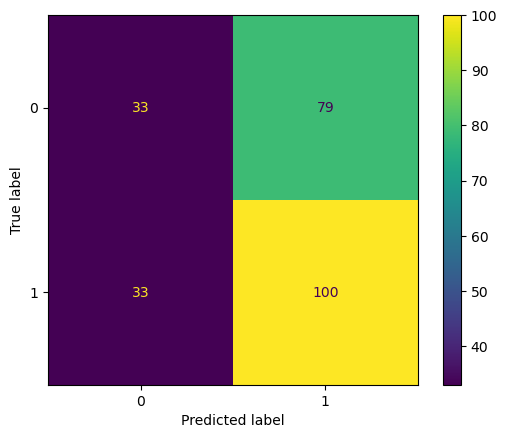

In [55]:
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()
plt.show()

# Rolling with only traditional 

In [180]:
game_data_roll.columns

Index(['SEASON_ID_home', 'TEAM_ID_home', 'TEAM_ABBREVIATION_home',
       'TEAM_NAME_home', 'GAME_ID', 'GAME_DATE_home', 'MATCHUP_home',
       'TEAM_ID_away', 'TEAM_ABBREVIATION_away', 'TEAM_NAME_away', 'WL',
       'FGM_rolling_diff', 'FGA_rolling_diff', 'FG_PCT_rolling_diff',
       'FG3M_rolling_diff', 'FG3A_rolling_diff', 'FG3_PCT_rolling_diff',
       'FTM_rolling_diff', 'FTA_rolling_diff', 'FT_PCT_rolling_diff',
       'OREB_rolling_diff', 'DREB_rolling_diff', 'REB_rolling_diff',
       'AST_rolling_diff', 'STL_rolling_diff', 'BLK_rolling_diff',
       'TOV_rolling_diff', 'PF_rolling_diff', 'PTS_rolling_diff',
       'PLUS_MINUS_rolling_diff', 'E_OFF_RATING_rolling_diff',
       'OFF_RATING_rolling_diff', 'E_DEF_RATING_rolling_diff',
       'DEF_RATING_rolling_diff', 'E_NET_RATING_rolling_diff',
       'NET_RATING_rolling_diff', 'AST_PCT_rolling_diff',
       'AST_TOV_rolling_diff', 'AST_RATIO_rolling_diff',
       'OREB_PCT_rolling_diff', 'DREB_PCT_rolling_diff',
       'REB_PC

In [60]:
cols = game_data_roll.columns[:30].to_list()

In [61]:
roll_tr = game_data_roll[cols]
roll_tr.drop(columns=['SEASON_ID_home',
 'TEAM_ID_home',
 'TEAM_ABBREVIATION_home',
 'TEAM_NAME_home',
 'GAME_ID',
 'GAME_DATE_home',
 'MATCHUP_home',
 'TEAM_ID_away',
 'TEAM_ABBREVIATION_away',
 'TEAM_NAME_away'], inplace=True)

/var/folders/n2/fnwtrxs13n10mlfx7sftx0t00000gn/T/ipykernel_56422/2430998515.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  roll_tr.drop(columns=['SEASON_ID_home',


In [62]:
from sklearn.model_selection import train_test_split

data = roll_tr[9:]
X = data.drop(columns=['WL'])
y = data['WL']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.2, random_state=42, stratify=y)

In [63]:
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression())
])

pipeline.fit(X_train, y_train)

Pipeline(steps=[('scaler', StandardScaler()), ('model', LogisticRegression())])

In [64]:
y_pred = pipeline.predict(X_test)

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.53      0.27      0.36       112
           1       0.56      0.80      0.66       133

    accuracy                           0.56       245
   macro avg       0.55      0.53      0.51       245
weighted avg       0.55      0.56      0.52       245



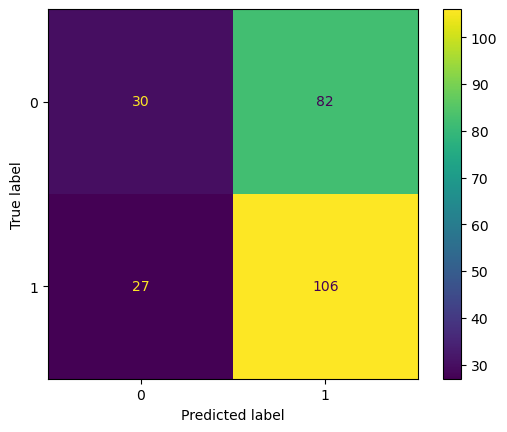

In [65]:
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()
plt.show()

# With advanced stats

In [66]:
cols = game_data_roll.columns[30:].to_list()
cols

['E_OFF_RATING_rolling_diff',
 'OFF_RATING_rolling_diff',
 'E_DEF_RATING_rolling_diff',
 'DEF_RATING_rolling_diff',
 'E_NET_RATING_rolling_diff',
 'NET_RATING_rolling_diff',
 'AST_PCT_rolling_diff',
 'AST_TOV_rolling_diff',
 'AST_RATIO_rolling_diff',
 'OREB_PCT_rolling_diff',
 'DREB_PCT_rolling_diff',
 'REB_PCT_rolling_diff',
 'E_TM_TOV_PCT_rolling_diff',
 'TM_TOV_PCT_rolling_diff',
 'EFG_PCT_rolling_diff',
 'TS_PCT_rolling_diff',
 'E_PACE_rolling_diff',
 'PACE_rolling_diff',
 'PACE_PER40_rolling_diff',
 'POSS_rolling_diff',
 'PIE_rolling_diff']

In [67]:
roll_ad = game_data_roll.drop(columns=['FGM_rolling_diff', 'FGA_rolling_diff', 'FG_PCT_rolling_diff',
       'FG3M_rolling_diff', 'FG3A_rolling_diff', 'FG3_PCT_rolling_diff',
       'FTM_rolling_diff', 'FTA_rolling_diff', 'FT_PCT_rolling_diff',
       'OREB_rolling_diff', 'DREB_rolling_diff', 'REB_rolling_diff',
       'AST_rolling_diff', 'STL_rolling_diff', 'BLK_rolling_diff',
       'TOV_rolling_diff', 'PF_rolling_diff', 'PTS_rolling_diff',
       'PLUS_MINUS_rolling_diff'])

In [68]:
roll_ad.drop(columns=['SEASON_ID_home',
 'TEAM_ID_home',
 'TEAM_ABBREVIATION_home',
 'TEAM_NAME_home',
 'GAME_ID',
 'GAME_DATE_home',
 'MATCHUP_home',
 'TEAM_ID_away',
 'TEAM_ABBREVIATION_away',
 'TEAM_NAME_away'], inplace=True)

In [69]:
from sklearn.model_selection import train_test_split

data = roll_ad[9:]
X = data.drop(columns=['WL'])
y = data['WL']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.2, random_state=42, stratify=y)

In [70]:
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression())
])

pipeline.fit(X_train, y_train)

Pipeline(steps=[('scaler', StandardScaler()), ('model', LogisticRegression())])

              precision    recall  f1-score   support

           0       0.50      0.24      0.33       112
           1       0.55      0.80      0.65       133

    accuracy                           0.54       245
   macro avg       0.53      0.52      0.49       245
weighted avg       0.53      0.54      0.50       245



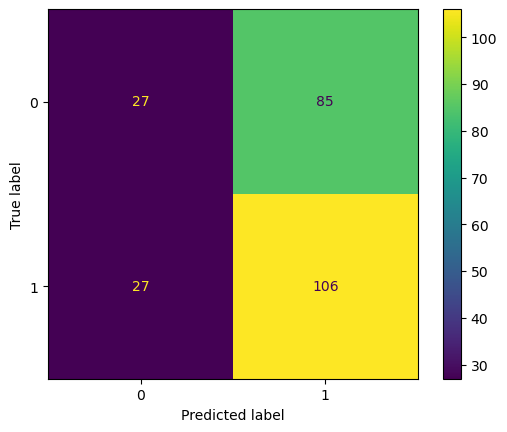

In [71]:
y_pred = pipeline.predict(X_test)

print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()
plt.show()

# This is what i got from the bugs that i fixed but im not sure what to do with all of this code

In [ ]:
for col in base_columns:
    home = col + "_home"
    away = col + "_away"
    if home in df.columns:
        print(f"droping: {home}")
        df.drop(columns=home, inplace=True)
    if away in df.columns:
        print(f"dropping: {away}")
        df.drop(columns=away, inplace=True)

df = df.drop(columns=['Unnamed: 0_x_home','Unnamed: 0_x_away','SEASON_ID_away','GAME_DATE_y','MATCHUP_away','MATCHUP_home','WL_y','home_away_away','Unnamed: 0_y_away','Unnamed: 0_y_home'])

df = df.rename(columns={
    'GAME_DATE_x':'GAME_DATE',
    'WL_x':'WL',
    'home_away_home':'home_away'})

drop_cols = ['FG_PCT','FG3_PCT','FT_PCT']
for col in drop_cols:
    home = col+"_home"
    away = col+"_away"
    if home in df.columns:
        df.drop(columns=home, inplace=True)
    if away in df.columns:
        df.drop(columns=away, inplace=True)

df.columns[5:-1]

df.drop(columns=['home_away','TEAM_ID_away','TEAM_NAME_away'], inplace=True)

df['WIN'] = (df['WL'] == 1).astype(int)

import matplotlib.pyplot as plt

t = df.dropna()
corr = t[t.columns[5:]].corr()
# Sort correlations with WIN
corr_with_win = corr[['WIN']].sort_values(by='WIN', ascending=False)

# Plot with larger figure size
plt.figure(figsize=(12,24))  # Increase height for many variables
sns.heatmap(corr_with_win, annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation with WIN (Home Team Victory)")
plt.tight_layout()
plt.show()

df.rename(columns={'GAME_DATE_x':'GAME_DATE'}, inplace=True
p = pd.read_csv('player_box_scores_2023.csv')

def clean_minutes_column(df):
    """
    Cleans the 'MIN' column by extracting the numeric part and converting it to float.
    """
    df['MIN'] = pd.to_numeric(
        df['MIN'].astype(str).str.split(':').str[0],
        errors='coerce'
    )
    # Fill nulls with 0 for players who didn't play
    df['MIN'].fillna(0, inplace=True)
    return df
p = clean_minutes_column(p)

def normalize(series):
    """Normalize a series to 0-1 range"""
    min_val = series.min()
    max_val = series.max()
    if max_val == min_val:
        return series * 0  # Return zeros if all values are the same
    return (series - min_val) / (max_val - min_val)

def calculate_player_importance(player_boxscores, cutoff_date=None, game_data=None):
    """Calculate importance score for each player based on averages up to cutoff_date (exclusive)
       Requires game_data to merge GAME_DATE into player_boxscores if not present."""
    # Merge GAME_DATE into player_boxscores if missing
    if 'GAME_DATE' not in player_boxscores.columns:
        # Make sure game_data has GAME_ID and GAME_DATE
        player_boxscores = player_boxscores.merge(
            game_data[['GAME_ID', 'GAME_DATE']],
            on='GAME_ID',
            how='left'
        )
    if cutoff_date is not None:
        player_boxscores = player_boxscores[player_boxscores['GAME_DATE'] < cutoff_date]
    if player_boxscores.empty:
        return pd.DataFrame(columns=['PLAYER_ID', 'MIN', 'PLUS_MINUS', 'PTS', 'AST', 'REB', 'TEAM_ID', 'importance_score'])
    season_stats = player_boxscores.groupby('PLAYER_ID').agg({
        'MIN': 'mean',
        'PLUS_MINUS': 'mean',
        'PTS': 'mean',
        'AST': 'mean',
        'REB': 'mean',
        'TEAM_ID': 'first'
    }).reset_index()
    season_stats['importance_score'] = (
        normalize(season_stats['MIN']) * 0.3 +
        normalize(season_stats['PLUS_MINUS']) * 0.2 +
        normalize(season_stats['PTS']) * 0.3 +
        normalize(season_stats['AST'] + season_stats['REB']) * 0.2
    )
    return season_stats

def identify_missing_players(game_id, team_id, player_boxscores, season_stats):
    """Identify missing players and their impact for a specific game"""
    # Get players who played in this game for this team
    game_players = player_boxscores[
        (player_boxscores['GAME_ID'] == game_id) &
        (player_boxscores['TEAM_ID'] == team_id)  # This TEAM_ID comes from original boxscores
    ]['PLAYER_ID'].unique()
    # Get team's regular rotation players
    rotation_players = season_stats[
        (season_stats['TEAM_ID'] == team_id) &  # This TEAM_ID matches with original boxscores
        (season_stats['MIN'] >= 15)
    ]['PLAYER_ID']
    # Find missing players
    missing_players = set(rotation_players) - set(game_players)
    # Calculate impact of missing players
    missing_impact = season_stats[
        season_stats['PLAYER_ID'].isin(missing_players)
    ]['importance_score'].sum()
    # Is the team's most important player missing?
    team_top_player = season_stats[
        season_stats['TEAM_ID'] == team_id
    ]['importance_score'].max()
    missing_star = any(
        season_stats[season_stats['PLAYER_ID'].isin(missing_players)]['importance_score'] >= team_top_player * 0.9
    )
    return len(missing_players), missing_impact, missing_star

def add_missing_player_features(game_data, player_boxscores):
    missing_home = []
    missing_away = []
    for idx, row in game_data.iterrows():
        cutoff_date = row['GAME_DATE']
        # Pass game_data so calculate_player_importance can merge GAME_DATE into player_boxscores
        season_stats = calculate_player_importance(
            player_boxscores,
            cutoff_date=cutoff_date,
            game_data=game_data
        )
        home_missing = identify_missing_players(
            row['GAME_ID'],
            row['TEAM_ID_home'],
            player_boxscores,
            season_stats
        )
        missing_home.append(home_missing)
        away_missing = identify_missing_players(
            row['GAME_ID'],
            row['TEAM_ID_away'],
            player_boxscores,
            season_stats
        )
        missing_away.append(away_missing)
    game_data[['missing_players_home', 'missing_impact_home', 'missing_star_home']] = pd.DataFrame(missing_home)
    game_data[['missing_players_away', 'missing_impact_away', 'missing_star_away']] = pd.DataFrame(missing_away)
    return game_data
    
dff = add_missing_player_features(df, p)
df['missing_star_home'] = df['missing_star_home'].map({'True': 1, 'False': 0})
df['missing_star_away'] = df['missing_star_away'].map({'True': 1, 'False': 0})
pca = df.drop(columns=['SEASON_ID_home','TEAM_ID_home','TEAM_NAME_home','GAME_ID','GAME_DATE','HOME_ELO_POST','AWAY_ELO_POST'])
pca['WIN'] = (pca['WL'] == 1).astype(int)
pca.drop(columns='WL', inplace=True)
correlations = pca.corr()[['WIN']].drop('WIN')  # drop target itself
# Sort correlations by absolute value (or just value) descending
correlations_sorted = correlations.reindex(correlations['WIN'].abs().sort_values(ascending=False).index)
## updates to missing players
p = pd.read_csv('player_box_scores_2023.csv')
def normalize(series):
    """Normalize a series to 0-1 range"""
    min_val = series.min()
    max_val = series.max()
    if max_val == min_val:
        return series * 0  # Return zeros if all values are the same
    return (series - min_val) / (max_val - min_val)
missing_home = []
missing_away = []
for idx, row in df.iterrows():
    if idx !=984:
        continue
    print(idx)
    cutoff_date = row['GAME_DATE']
    game_id = row['GAME_ID']
    team_id = row['TEAM_ID_home']
    # Pass game_data so calculate_player_importance can merge GAME_DATE into player_boxscores
    # season_stats = calculate_player_importance(
    #     player_boxscores,
    #     cutoff_date=cutoff_date,
    #     game_data=game_data
    # )
    """CALCULATE PLAYER IMPORTANCE"""
     # Merge GAME_DATE into player_boxscores if missing
    if 'GAME_DATE' not in p.columns:
        # Make sure game_data has GAME_ID and GAME_DATE
        player_boxscores = p.merge(
            df[['GAME_ID', 'GAME_DATE']],
            on='GAME_ID',
            how='left'
        )
    player_boxscores_for_missingplayers = player_boxscores
    if cutoff_date is not None:
        player_boxscores = player_boxscores[player_boxscores['GAME_DATE'] < cutoff_date]
    if player_boxscores.empty:
        player_boxscores = pd.DataFrame(columns=['PLAYER_ID', 'MIN', 'PLUS_MINUS', 'PTS', 'AST', 'REB', 'TEAM_ID', 'importance_score'])
    player_boxscores['MIN'] = player_boxscores['MIN'].str.split('.').str[0]
    player_boxscores['MIN'] = player_boxscores['MIN'].fillna(0)
    player_boxscores['MIN'] = player_boxscores['MIN'].astype(int)
    season_stats = player_boxscores.groupby('PLAYER_ID').agg({
        'MIN': 'mean',
        'PLUS_MINUS': 'mean',
        'PTS': 'mean',
        'AST': 'mean',
        'REB': 'mean',
        'TEAM_ID': 'first'
    }).reset_index()
    season_stats['importance_score'] = (
        normalize(season_stats['MIN']) * 0.3 +
        normalize(season_stats['PLUS_MINUS']) * 0.2 +
        normalize(season_stats['PTS']) * 0.3 +
        normalize(season_stats['AST'] + season_stats['REB']) * 0.2
    )
    # home_missing = identify_missing_players(
    #     row['GAME_ID'],
    #     row['TEAM_ID_home'],
    #     player_boxscores,
    #     season_stats
    # )
    """ IDENTIFY MISSING PLAYERS """
    # Get players who played in this game for this team
    game_players = player_boxscores_for_missingplayers[
        (player_boxscores_for_missingplayers['GAME_ID'] == game_id) &
        (player_boxscores_for_missingplayers['TEAM_ID'] == team_id)  # This TEAM_ID comes from original boxscores
    ]['PLAYER_ID'].unique()
    # Get team's regular rotation players
    rotation_players = season_stats[
        (season_stats['TEAM_ID'] == team_id) &  # This TEAM_ID matches with original boxscores
        (season_stats['MIN'] >= 15)
    ]['PLAYER_ID']
    # Find missing players
    missing_players = set(rotation_players) - set(game_players)
    # Calculate impact of missing players
    missing_impact = season_stats[
        season_stats['PLAYER_ID'].isin(missing_players)
    ]['importance_score'].sum()
    # Is the team's most important player missing?
    team_top_player = season_stats[
        season_stats['TEAM_ID'] == team_id
    ]['importance_score'].max()
    missing_star = any(
        season_stats[season_stats['PLAYER_ID'].isin(missing_players)]['importance_score'] >= team_top_player * 0.9
    )
#     away_missing = identify_missing_players(
#         row['GAME_ID'],
#         row['TEAM_ID_away'],
#         player_boxscores,
#         season_stats
#     )
#     missing_away.append(away_missing)
# game_data[['missing_players_home', 'missing_impact_home', 'missing_star_home']] = pd.DataFrame(missing_home)
# game_data[['missing_players_away', 'missing_impact_away', 'missing_star_away']] = pd.DataFrame(missing_away)